# Notebook expérimental  pour la détection des attaques DDoS sur CIC-DDoS2019



## Objectifs expérimentaux
Ce notebook répond à quatre questions scientifiques :
1. Comment échantillonner les données pour que le sous-ensemble soit plus représentatif ?
2. Quelle est l’importance de la structure par groupes dans le dataset avant la modélisation ?
3. À quel point l’évaluation row-wise est-elle optimiste par rapport à l’évaluation group-aware ?
4. Le LSTM reste-t-il justifié une fois que l’on ajoute des baselines tabulaires plus fortes et des vérifications de features raccourcis ?

## Portion du dataset utilisée
- `01-12/DrDoS_DNS.csv`
- `01-12/DrDoS_NTP.csv`
- `01-12/DrDoS_NetBIOS.csv`
- `03-11/Portmap.csv`

## Classes cibles
- `BENIGN`
- `DrDoS_DNS`
- `DrDoS_NTP`
- `DrDoS_NetBIOS`
- `Portmap`

## Note méthodologique importante
CIC-DDoS2019 est avant tout un dataset **tabulaire de flux réseau**. Le LSTM y est donc étudié comme un modèle séquentiel appliqué à des flux ordonnés par `source_ip` et `timestamp`, mais cette hypothèse reste une approximation méthodologique qu’il faut discuter honnêtement.

In [2]:
# Imports and runtime configuration.

from pathlib import Path
import random
import re
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, average_precision_score, classification_report, confusion_matrix, f1_score, make_scorer, roc_auc_score
from sklearn.model_selection import GroupShuffleSplit, RandomizedSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, StandardScaler, label_binarize
from torch import nn
from torch.utils.data import DataLoader, Dataset

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.max_columns', 120)
pd.set_option('display.width', 180)

SEED = 42
BASE_DIR = Path.cwd()
DATA_FILES = [
    BASE_DIR / '01-12' / 'DrDoS_DNS.csv',
    BASE_DIR / '01-12' / 'DrDoS_NTP.csv',
    BASE_DIR / '01-12' / 'DrDoS_NetBIOS.csv',
    BASE_DIR / '03-11' / 'Portmap.csv',
]

# Controlled subset and training settings.
SCAN_CHUNK_SIZE = 100_000
SELECTED_CHUNKS_PER_FILE = 6
MAX_ROWS_PER_FILE = 2_000
GROUP_TEST_SIZE = 0.20
GROUP_VALIDATION_SIZE = 0.20
MIN_GROUPS_PER_SPLIT = 3
ROWWISE_SEQUENCE_LENGTH = 5
GROUP_SEQUENCE_LENGTHS = [5, 10]
BATCH_SIZE = 256
LSTM_HIDDEN_SIZE = 48
LSTM_DROPOUT = 0.25
LSTM_LEARNING_RATE = 1e-3
LSTM_MAX_EPOCHS = 8
LSTM_PATIENCE = 3
RF_TREES = 160


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Base directory:', BASE_DIR)
print('Device:', DEVICE)
print('Subset design:', MAX_ROWS_PER_FILE, 'rows per file from', SELECTED_CHUNKS_PER_FILE, 'distributed chunks')

Base directory: C:\Users\nourg\Downloads\archive (1)
Device: cpu
Subset design: 2000 rows per file from 6 distributed chunks


## Principes méthodologiques du notebook

Ce notebook suit une démarche expérimentale  afin de produire des résultats interprétables et défendables  :
- **L’échantillonnage** est réparti sur une plus grande partie du fichier afin d’éviter de dépendre uniquement des premiers chunks.
- **Les diagnostics de groupes** sont calculés avant toute modélisation afin que la faible diversité des `source_ip` soit visible très tôt.
- **Le split group-aware** est validé et évalué au lieu d’être accepté aveuglément.
- **Les baselines tabulaires** incluent Random Forest en plus de Logistic Regression.
- **L’ablation de features** est étendue au-delà de `inbound` lorsque d’autres raccourcis potentiels sont détectés.
- **L’interprétation** distingue explicitement la performance de benchmark de la performance de robustesse.

L’objectif n’est pas seulement d’obtenir de bons scores, mais de produire des conclusions scientifiquement solides sur ce dataset.

## Fonctions utilitaires

Toute la logique du projet utilisée ci-dessous est intégrée directement dans le notebook afin qu’il reste totalement autonome.

In [3]:
def sanitize_name(name: str) -> str:
    name = str(name).strip().lower()
    name = re.sub(r'[^a-z0-9]+', '_', name)
    name = re.sub(r'_+', '_', name).strip('_')
    return name or 'unnamed'


def standardize_columns(columns):
    seen = {}
    cleaned = []
    for column in columns:
        base = sanitize_name(column)
        count = seen.get(base, 0)
        new_name = f'{base}_{count}' if count else base
        seen[base] = count + 1
        cleaned.append(new_name)
    return cleaned


def infer_target_column(columns):
    for candidate in ['label', 'target', 'class', 'attack', 'category']:
        for column in columns:
            if sanitize_name(column) == candidate:
                return column
    raise ValueError('Could not infer the target column automatically.')


def find_duplicate_columns(df):
    duplicate_columns = []
    signatures = {}
    for column in df.columns:
        signature = tuple(df[column].astype(str).fillna('<NA>').head(3000).tolist())
        if signature in signatures:
            duplicate_columns.append(column)
        else:
            signatures[signature] = column
    return duplicate_columns


def load_streaming_subset(file_path, max_rows=MAX_ROWS_PER_FILE, chunk_size=SCAN_CHUNK_SIZE, selected_chunks=SELECTED_CHUNKS_PER_FILE):
    attack_cap_per_source = max(60, max_rows // 12)
    benign_cap = max_rows
    benign_pool = pd.DataFrame()
    attack_pools = {}
    seen_chunks = 0
    label_col_name = None
    src_col_name = None

    for chunk_idx, chunk in enumerate(pd.read_csv(file_path, chunksize=chunk_size, low_memory=False)):
        seen_chunks += 1
        if label_col_name is None:
            label_col_name = next(c for c in chunk.columns if str(c).strip().lower() == 'label')
            src_col_name = next(c for c in chunk.columns if str(c).strip().lower() == 'source ip')

        label_values = chunk[label_col_name].astype(str).str.strip()
        attack_chunk = chunk[label_values != 'BENIGN'].copy()
        benign_chunk = chunk[label_values == 'BENIGN'].copy()

        if not attack_chunk.empty:
            for source_ip, group_df in attack_chunk.groupby(src_col_name, dropna=False):
                current = attack_pools.get(source_ip, pd.DataFrame())
                merged = pd.concat([current, group_df], ignore_index=True)
                if len(merged) > attack_cap_per_source:
                    merged = merged.sample(n=attack_cap_per_source, random_state=SEED + chunk_idx)
                attack_pools[source_ip] = merged.reset_index(drop=True)

        if not benign_chunk.empty:
            merged_benign = pd.concat([benign_pool, benign_chunk], ignore_index=True)
            if len(merged_benign) > benign_cap:
                merged_benign = merged_benign.sample(n=benign_cap, random_state=SEED + 50_000 + chunk_idx)
            benign_pool = merged_benign.reset_index(drop=True)

    attack_df = pd.concat(list(attack_pools.values()), ignore_index=True) if attack_pools else pd.DataFrame(columns=benign_pool.columns)
    remaining_budget = max(0, max_rows - len(attack_df))
    if len(benign_pool) > remaining_budget:
        benign_pool = benign_pool.sample(n=remaining_budget, random_state=SEED).reset_index(drop=True)
    df = pd.concat([attack_df, benign_pool], ignore_index=True)
    if len(df) > max_rows:
        df = df.sample(n=max_rows, random_state=SEED).reset_index(drop=True)
    df['__source_file__'] = file_path.as_posix()
    sampling_meta = {
        'file': file_path.as_posix(),
        'chunks_scanned': int(seen_chunks),
        'rows_loaded': int(len(df)),
        'attack_source_ip_in_subset': int(len(attack_pools)),
        'attack_rows_retained': int(len(attack_df)),
        'benign_rows_retained': int(len(benign_pool)),
        'sampling_strategy': 'one_pass_streaming_attack_aware',
    }
    return df, sampling_meta


def summarize_raw_dataframe(df):
    target_col = infer_target_column(df.columns)
    return {
        'shape': df.shape,
        'memory_mb': round(df.memory_usage(deep=True).sum() / (1024 ** 2), 2),
        'target_column': target_col,
        'label_distribution': df[target_col].astype(str).str.strip().value_counts().to_dict(),
    }


def preprocess_dataframe(raw_df):
    df = raw_df.copy()
    original_columns = list(df.columns)
    df.columns = standardize_columns(df.columns)
    target_column = sanitize_name(infer_target_column(original_columns))

    if 'simillarhttp' in df.columns:
        df['simillarhttp'] = pd.to_numeric(df['simillarhttp'], errors='coerce')

    df[target_column] = df[target_column].astype(str).str.strip()
    df[target_column] = df[target_column].replace({'DNS': 'DrDoS_DNS', 'NTP': 'DrDoS_NTP', 'NetBIOS': 'DrDoS_NetBIOS'})

    duplicate_rows_removed = int(df.duplicated().sum())
    df = df.drop_duplicates().reset_index(drop=True)

    duplicate_columns = find_duplicate_columns(df)
    if duplicate_columns:
        df = df.drop(columns=duplicate_columns)

    protected = {target_column, 'source_ip', 'destination_ip', 'timestamp', 'flow_id', '__source_file__', 'source_file'}
    object_cols = [c for c in df.columns if df[c].dtype == 'object' and c not in protected]
    converted_numeric = []
    for col in object_cols:
        converted = pd.to_numeric(df[col], errors='coerce')
        if converted.notna().mean() > 0.9:
            df[col] = converted
            converted_numeric.append(col)

    df = df.replace([np.inf, -np.inf], np.nan)

    constant_columns = [c for c in df.columns if c != target_column and df[c].nunique(dropna=False) <= 1]
    if constant_columns:
        df = df.drop(columns=constant_columns)

    near_constant_columns = []
    for c in df.columns:
        if c == target_column or c in ['source_ip', 'destination_ip', 'timestamp', '__source_file__', 'source_file']:
            continue
        freq = df[c].value_counts(normalize=True, dropna=False)
        if len(freq) > 0 and freq.iloc[0] >= 0.995:
            near_constant_columns.append(c)
    if near_constant_columns:
        df = df.drop(columns=near_constant_columns)

    if 'timestamp' in df.columns:
        df['timestamp'] = pd.to_datetime(df['timestamp'], errors='coerce')

    leakage_candidates = ['unnamed_0', 'flow_id', 'source_ip', 'destination_ip', 'source_port', 'destination_port', 'timestamp', 'simillarhttp']
    summary = {
        'original_shape': raw_df.shape,
        'final_shape': df.shape,
        'target_column': target_column,
        'duplicate_rows_removed': duplicate_rows_removed,
        'duplicate_columns_removed': duplicate_columns,
        'converted_numeric_columns': converted_numeric,
        'constant_columns_removed': constant_columns,
        'near_constant_columns_removed': near_constant_columns,
        'missing_values_top10': df.isna().sum().sort_values(ascending=False).head(10).to_dict(),
        'label_distribution_after_cleaning': df[target_column].value_counts().to_dict(),
        'candidate_leakage_columns': [c for c in leakage_candidates if c in df.columns],
    }
    return df, summary


def select_feature_columns(df, target_column):
    excluded = {target_column, 'unnamed_0', 'flow_id', 'source_ip', 'destination_ip', 'source_port', 'destination_port', 'timestamp', 'simillarhttp', '__source_file__', 'source_file'}
    return [c for c in df.columns if c not in excluded and pd.api.types.is_numeric_dtype(df[c])]


def summarize_group_structure(df, target_column, group_column='source_ip'):
    work_df = df[df[group_column].notna()].copy()
    group_sizes = work_df.groupby(group_column).size().sort_values(ascending=False)
    unique_groups_per_class = work_df.groupby(target_column)[group_column].nunique().sort_values()
    largest_group_by_class = work_df.groupby([target_column, group_column]).size().reset_index(name='rows').sort_values([target_column, 'rows'], ascending=[True, False])
    top_groups = largest_group_by_class.groupby(target_column).head(5).copy()
    top_groups['class_total_rows'] = top_groups.groupby(target_column)['rows'].transform('sum')
    concentration = work_df.groupby(target_column).apply(lambda g: g.groupby(group_column).size().max() / len(g)).rename('largest_group_share').reset_index()
    warning_classes = unique_groups_per_class[unique_groups_per_class < 3].index.tolist()
    summary = {
        'unique_groups_per_class': unique_groups_per_class.to_dict(),
        'group_size_mean': float(group_sizes.mean()),
        'group_size_median': float(group_sizes.median()),
        'group_size_max': int(group_sizes.max()),
        'largest_group_share_by_class': dict(zip(concentration[target_column], concentration['largest_group_share'])),
        'warning_classes': warning_classes,
    }
    return summary, group_sizes, top_groups

In [4]:
def compute_class_weights(y_encoded):
    classes, counts = np.unique(y_encoded, return_counts=True)
    total = counts.sum()
    return {int(cls): float(total / (len(classes) * count)) for cls, count in zip(classes, counts)}


def prepare_split(train_df, test_df, target_column, feature_columns):
    label_encoder = LabelEncoder()
    y_train = label_encoder.fit_transform(train_df[target_column])
    y_test = label_encoder.transform(test_df[target_column])
    imputer = SimpleImputer(strategy='median')
    scaler = StandardScaler()
    X_train = scaler.fit_transform(imputer.fit_transform(train_df[feature_columns])).astype(np.float32)
    X_test = scaler.transform(imputer.transform(test_df[feature_columns])).astype(np.float32)
    return {
        'X_train': X_train,
        'X_test': X_test,
        'y_train': y_train.astype(np.int64),
        'y_test': y_test.astype(np.int64),
        'label_encoder': label_encoder,
        'class_weights': compute_class_weights(y_train),
        'feature_columns': feature_columns,
        'train_df': train_df.reset_index(drop=True),
        'test_df': test_df.reset_index(drop=True),
    }


def stratified_rowwise_split(df, target_column, test_size=0.2):
    train_df, test_df = train_test_split(df, test_size=test_size, random_state=SEED, stratify=df[target_column])
    return train_df.reset_index(drop=True), test_df.reset_index(drop=True)


def score_group_split(train_df, test_df, target_column, group_column='source_ip', target_test_size=GROUP_TEST_SIZE):
    all_classes = sorted(pd.concat([train_df[target_column], test_df[target_column]]).unique())
    overlap = len(set(train_df[group_column].dropna()) & set(test_df[group_column].dropna()))
    class_presence_ok = set(train_df[target_column]) == set(test_df[target_column]) == set(all_classes)
    test_ratio = len(test_df) / max(1, len(train_df) + len(test_df))
    test_groups = test_df[group_column].nunique()
    train_groups = train_df[group_column].nunique()
    min_class_support = int(test_df[target_column].value_counts().min()) if len(test_df) else 0
    score = abs(test_ratio - target_test_size)
    return {
        'overlap': overlap,
        'class_presence_ok': class_presence_ok,
        'test_ratio': float(test_ratio),
        'train_groups': int(train_groups),
        'test_groups': int(test_groups),
        'min_test_class_support': min_class_support,
        'score': float(score),
        'is_valid': overlap == 0 and class_presence_ok and train_groups >= MIN_GROUPS_PER_SPLIT and test_groups >= MIN_GROUPS_PER_SPLIT,
    }


def build_class_covering_split(df, target_column, group_column='source_ip', target_test_size=GROUP_TEST_SIZE):
    work_df = df[df[group_column].notna()].copy().reset_index(drop=True)
    group_class_counts = work_df.groupby([group_column, target_column]).size().unstack(fill_value=0)
    class_to_groups = {
        cls: list(group_class_counts.index[group_class_counts[cls] > 0])
        for cls in group_class_counts.columns
    }
    remaining_groups = set(group_class_counts.index)
    selected_test_groups = set()

    for cls, groups in class_to_groups.items():
        candidate_groups = sorted(groups, key=lambda g: group_class_counts.loc[g, cls])
        chosen = None
        for group in candidate_groups:
            other_groups = [g for g in groups if g != group and g in remaining_groups]
            if other_groups:
                chosen = group
                break
        if chosen is not None:
            selected_test_groups.add(chosen)
            remaining_groups.discard(chosen)

    target_test_rows = int(len(work_df) * target_test_size)
    benign_candidates = [g for g in remaining_groups if group_class_counts.loc[g].sum() == group_class_counts.loc[g].get('BENIGN', 0)]
    benign_candidates = sorted(benign_candidates, key=lambda g: group_class_counts.loc[g].sum())
    current_test_rows = int(work_df[work_df[group_column].isin(selected_test_groups)].shape[0])
    remaining_benign_groups = len(benign_candidates)
    for group in benign_candidates:
        if current_test_rows >= target_test_rows:
            break
        if remaining_benign_groups <= MIN_GROUPS_PER_SPLIT:
            break
        selected_test_groups.add(group)
        current_test_rows += int(group_class_counts.loc[group].sum())
        remaining_benign_groups -= 1

    train_df = work_df[~work_df[group_column].isin(selected_test_groups)].reset_index(drop=True)
    test_df = work_df[work_df[group_column].isin(selected_test_groups)].reset_index(drop=True)
    diag = score_group_split(train_df, test_df, target_column, group_column=group_column, target_test_size=target_test_size)
    diag['construction'] = 'class_covering_seeded'
    return train_df, test_df, diag


def robust_group_split(df, target_column, group_column='source_ip', test_size=GROUP_TEST_SIZE, n_trials=120):
    candidates = []
    seeded_train, seeded_test, seeded_diag = build_class_covering_split(df, target_column, group_column=group_column, target_test_size=test_size)
    candidates.append((seeded_train, seeded_test, seeded_diag))

    groups = df[group_column]
    for trial in range(n_trials):
        splitter = GroupShuffleSplit(n_splits=1, test_size=test_size, random_state=SEED + trial)
        train_idx, test_idx = next(splitter.split(df, df[target_column], groups))
        train_df = df.iloc[train_idx].reset_index(drop=True)
        test_df = df.iloc[test_idx].reset_index(drop=True)
        diag = score_group_split(train_df, test_df, target_column, group_column=group_column, target_test_size=test_size)
        diag['construction'] = f'group_shuffle_seed_{SEED + trial}'
        candidates.append((train_df, test_df, diag))

    valid_candidates = [item for item in candidates if item[2]['is_valid']]
    if valid_candidates:
        best_train, best_test, best_diag = min(valid_candidates, key=lambda item: (item[2]['score'], -item[2]['min_test_class_support']))
        best_diag['status'] = 'valid'
        return best_train, best_test, best_diag

    best_train, best_test, best_diag = min(candidates, key=lambda item: (0 if item[2]['class_presence_ok'] else 1, item[2]['score']))
    best_diag['status'] = 'fallback_best_feasible'
    return best_train, best_test, best_diag


def build_internal_validation_split(train_df, target_column, group_column='source_ip', validation_size=GROUP_VALIDATION_SIZE):
    inner_train_df, val_df, diag = robust_group_split(train_df, target_column, group_column=group_column, test_size=validation_size, n_trials=80)
    if diag['status'] == 'valid':
        diag['strategy'] = 'group_aware'
        return inner_train_df, val_df, diag
    row_train_df, row_val_df = train_test_split(train_df, test_size=validation_size, random_state=SEED, stratify=train_df[target_column])
    diag['strategy'] = 'rowwise_fallback_due_to_group_infeasibility'
    diag['warning'] = 'Class-preserving group-aware validation was infeasible inside the training partition.'
    return row_train_df.reset_index(drop=True), row_val_df.reset_index(drop=True), diag


def build_sequences(X, y, metadata_df, sequence_length, group_column='source_ip', time_column='timestamp'):
    temp = metadata_df[[group_column, time_column]].copy()
    temp['row_index'] = np.arange(len(temp))
    temp[time_column] = pd.to_datetime(temp[time_column], errors='coerce').fillna(pd.Timestamp('1970-01-01'))
    sequences = np.zeros((len(temp), sequence_length, X.shape[1]), dtype=np.float32)
    labels = np.zeros(len(temp), dtype=np.int64)
    for _, group_df in temp.groupby(group_column, dropna=False):
        ordered = group_df.sort_values([time_column, 'row_index'])
        idxs = ordered['row_index'].tolist()
        for pos, idx in enumerate(idxs):
            start = max(0, pos - sequence_length + 1)
            history = idxs[start:pos + 1]
            seq = X[history]
            sequences[idx, -len(seq):, :] = seq
            labels[idx] = y[idx]
    return sequences, labels


class FlowSequenceDataset(Dataset):
    def __init__(self, X_seq, y):
        self.X_seq = torch.tensor(X_seq, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X_seq[idx], self.y[idx]


class LSTMClassifier(nn.Module):
    def __init__(self, input_size, hidden_size, num_classes, dropout=LSTM_DROPOUT):
        super().__init__()
        self.lstm = nn.LSTM(input_size=input_size, hidden_size=hidden_size, batch_first=True)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_size, num_classes)

    def forward(self, x):
        output, _ = self.lstm(x)
        return self.fc(self.dropout(output[:, -1, :]))


def make_loader(X_seq, y, batch_size=BATCH_SIZE, shuffle=False):
    return DataLoader(FlowSequenceDataset(X_seq, y), batch_size=batch_size, shuffle=shuffle)


In [5]:
def evaluate_classifier(model_name, y_true, y_pred, y_proba, classes):
    class_labels = np.arange(len(classes))
    metrics = {
        'model': model_name,
        'accuracy': float(accuracy_score(y_true, y_pred)),
        'f1_weighted': float(f1_score(y_true, y_pred, average='weighted', zero_division=0, labels=class_labels)),
        'f1_macro': float(f1_score(y_true, y_pred, average='macro', zero_division=0, labels=class_labels)),
        'classification_report': classification_report(y_true, y_pred, labels=class_labels, target_names=list(classes), output_dict=True, zero_division=0),
        'confusion_matrix': confusion_matrix(y_true, y_pred, labels=class_labels).tolist(),
    }
    if y_proba is not None and len(classes) > 2:
        y_true_bin = label_binarize(y_true, classes=class_labels)
        metrics['roc_auc_ovr_weighted'] = float(roc_auc_score(y_true_bin, y_proba, average='weighted', multi_class='ovr'))
        metrics['pr_auc_weighted'] = float(average_precision_score(y_true_bin, y_proba, average='weighted'))
    return metrics


def plot_confusion(ax, cm, labels, title):
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels, ax=ax, cbar=False)
    ax.set_title(title)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')
    ax.tick_params(axis='x', rotation=30)
    ax.tick_params(axis='y', rotation=0)


def train_logistic(train_df, test_df, target_column, feature_columns):
    prepared = prepare_split(train_df, test_df, target_column, feature_columns)
    model = LogisticRegression(max_iter=500, multi_class='auto', class_weight=prepared['class_weights'], C=0.3)
    model.fit(prepared['X_train'], prepared['y_train'])
    pred = model.predict(prepared['X_test'])
    proba = model.predict_proba(prepared['X_test'])
    metrics = evaluate_classifier('logistic_regression', prepared['y_test'], pred, proba, prepared['label_encoder'].classes_)
    return model, metrics, prepared


def train_random_forest(train_df, test_df, target_column, feature_columns, rf_params=None):
    prepared = prepare_split(train_df, test_df, target_column, feature_columns)
    base_params = {
        'n_estimators': RF_TREES,
        'max_depth': 18,
        'min_samples_split': 4,
        'min_samples_leaf': 2,
        'max_features': 'sqrt',
        'random_state': SEED,
        'class_weight': 'balanced_subsample',
        'n_jobs': -1,
    }
    if rf_params:
        base_params.update(rf_params)
    model = RandomForestClassifier(**base_params)
    model.fit(prepared['X_train'], prepared['y_train'])
    pred = model.predict(prepared['X_test'])
    proba = model.predict_proba(prepared['X_test'])
    metrics = evaluate_classifier('random_forest', prepared['y_test'], pred, proba, prepared['label_encoder'].classes_)
    metrics['params'] = {k: v for k, v in base_params.items() if k not in {'random_state', 'n_jobs'}}
    importance_df = pd.DataFrame({'feature': feature_columns, 'importance': model.feature_importances_}).sort_values('importance', ascending=False)
    return model, metrics, prepared, importance_df


def tune_random_forest_rowwise(train_df, test_df, target_column, feature_columns, n_iter=10):
    scorer = make_scorer(f1_score, average='weighted', zero_division=0)
    cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
    pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('rf', RandomForestClassifier(random_state=SEED, class_weight='balanced_subsample', n_jobs=-1)),
    ])
    param_distributions = {
        'rf__n_estimators': [100, 150, 200, 250, 300],
        'rf__max_depth': [10, 14, 18, 24, None],
        'rf__min_samples_split': [2, 4, 6, 8],
        'rf__min_samples_leaf': [1, 2, 3, 4],
        'rf__max_features': ['sqrt', 'log2', 0.5, 0.7],
    }
    search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=param_distributions,
        n_iter=n_iter,
        scoring=scorer,
        cv=cv,
        random_state=SEED,
        n_jobs=-1,
        verbose=0,
    )
    search.fit(train_df[feature_columns], train_df[target_column])
    best_model = search.best_estimator_
    pred = best_model.predict(test_df[feature_columns])
    proba = best_model.predict_proba(test_df[feature_columns])
    label_encoder = LabelEncoder()
    label_encoder.fit(train_df[target_column])
    y_test = label_encoder.transform(test_df[target_column])
    pred_encoded = label_encoder.transform(pred)
    metrics = evaluate_classifier('random_forest_tuned', y_test, pred_encoded, proba, label_encoder.classes_)
    metrics['best_cv_weighted_f1'] = float(search.best_score_)
    metrics['best_params'] = {k.replace('rf__', ''): v for k, v in search.best_params_.items()}
    return best_model, metrics, search


def train_lstm(train_df, test_df, target_column, feature_columns, sequence_lengths, hidden_sizes=None, dropouts=None):
    if hidden_sizes is None:
        hidden_sizes = [LSTM_HIDDEN_SIZE]
    if dropouts is None:
        dropouts = [LSTM_DROPOUT]

    inner_train_df, val_df, validation_diag = build_internal_validation_split(train_df, target_column, group_column='source_ip', validation_size=GROUP_VALIDATION_SIZE)
    prepared_inner = prepare_split(inner_train_df, val_df, target_column, feature_columns)
    prepared_full = prepare_split(train_df, test_df, target_column, feature_columns)

    best = None
    histories = {}
    for sequence_length in sequence_lengths:
        for hidden_size in hidden_sizes:
            for dropout in dropouts:
                X_train_seq, y_train_seq = build_sequences(prepared_inner['X_train'], prepared_inner['y_train'], prepared_inner['train_df'], sequence_length)
                X_val_seq, y_val_seq = build_sequences(prepared_inner['X_test'], prepared_inner['y_test'], prepared_inner['test_df'], sequence_length)
                train_loader = make_loader(X_train_seq, y_train_seq, shuffle=True)
                val_loader = make_loader(X_val_seq, y_val_seq, shuffle=False)

                model = LSTMClassifier(input_size=X_train_seq.shape[-1], hidden_size=hidden_size, num_classes=len(prepared_inner['label_encoder'].classes_), dropout=dropout).to(DEVICE)
                weight_tensor = torch.tensor([prepared_inner['class_weights'][i] for i in range(len(prepared_inner['label_encoder'].classes_))], dtype=torch.float32, device=DEVICE)
                criterion = nn.CrossEntropyLoss(weight=weight_tensor)
                optimizer = torch.optim.Adam(model.parameters(), lr=LSTM_LEARNING_RATE)

                best_state = None
                best_val_f1 = -np.inf
                history = {'train_loss': [], 'val_loss': [], 'val_weighted_f1': []}
                patience_counter = 0

                for _ in range(LSTM_MAX_EPOCHS):
                    model.train()
                    train_losses = []
                    for xb, yb in train_loader:
                        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
                        optimizer.zero_grad()
                        logits = model(xb)
                        loss = criterion(logits, yb)
                        loss.backward()
                        optimizer.step()
                        train_losses.append(loss.item())

                    model.eval()
                    val_losses = []
                    val_pred = []
                    with torch.no_grad():
                        for xb, yb in val_loader:
                            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
                            logits = model(xb)
                            probs = torch.softmax(logits, dim=1)
                            val_losses.append(criterion(logits, yb).item())
                            val_pred.extend(torch.argmax(probs, dim=1).cpu().numpy())
                    val_f1 = f1_score(y_val_seq, np.array(val_pred), average='weighted', zero_division=0, labels=np.arange(len(prepared_inner['label_encoder'].classes_)))
                    history['train_loss'].append(float(np.mean(train_losses)))
                    history['val_loss'].append(float(np.mean(val_losses)))
                    history['val_weighted_f1'].append(float(val_f1))

                    if val_f1 > best_val_f1:
                        best_val_f1 = val_f1
                        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
                        patience_counter = 0
                    else:
                        patience_counter += 1
                        if patience_counter >= LSTM_PATIENCE:
                            break

                model.load_state_dict(best_state)
                config_key = (sequence_length, hidden_size, dropout)
                histories[config_key] = history
                candidate = {
                    'model': model,
                    'sequence_length': sequence_length,
                    'hidden_size': hidden_size,
                    'dropout': dropout,
                    'validation_f1': float(best_val_f1),
                }
                if best is None or candidate['validation_f1'] > best['validation_f1']:
                    best = candidate

    X_test_seq, y_test_seq = build_sequences(prepared_full['X_test'], prepared_full['y_test'], prepared_full['test_df'], best['sequence_length'])
    test_loader = make_loader(X_test_seq, y_test_seq, shuffle=False)
    best['model'].eval()
    pred = []
    proba = []
    with torch.no_grad():
        for xb, _ in test_loader:
            xb = xb.to(DEVICE)
            logits = best['model'](xb)
            probs = torch.softmax(logits, dim=1)
            pred.extend(torch.argmax(probs, dim=1).cpu().numpy())
            proba.extend(probs.cpu().numpy())

    metrics = evaluate_classifier('lstm', y_test_seq, np.array(pred), np.array(proba), prepared_full['label_encoder'].classes_)
    metrics['best_sequence_length'] = int(best['sequence_length'])
    metrics['best_hidden_size'] = int(best['hidden_size'])
    metrics['best_dropout'] = float(best['dropout'])
    metrics['best_validation_weighted_f1'] = float(best['validation_f1'])
    metrics['validation_strategy'] = validation_diag['strategy']
    if 'warning' in validation_diag:
        metrics['validation_warning'] = validation_diag['warning']
    return best['model'], metrics, histories, prepared_full, validation_diag


## Chargement des données avec une stratégie d’échantillonnage distribuée plus rapide

### Ce qui a changé et pourquoi
La version  précédente essayait d’estimer la couverture des chunks en scannant les fichiers plusieurs fois, ce qui rendait l’exécution trop lente.

Ce notebook utilise maintenant une **stratégie d’échantillonnage en flux sur un seul passage** :
- scanner chaque fichier CSV une seule fois
- conserver un échantillon borné du trafic bénin sur l’ensemble du fichier
- conserver des échantillons bornés pour chaque `source_ip` d’attaque observé
- fusionner ces échantillons dans un sous-ensemble contrôlé par fichier

Il s’agit toujours d’un sous-ensemble, mais il est plus défendable que de ne prendre que les premiers chunks et beaucoup plus pratique qu’un scan complet répété. Il améliore la couverture des sources tout en gardant un temps d’exécution raisonnable sur Colab et en local.

In [6]:
sampled_frames = []
sampling_records = []
for path in DATA_FILES:
    df_piece, sample_meta = load_streaming_subset(path)
    sampled_frames.append(df_piece)
    sampling_records.append(sample_meta)

sampling_df = pd.DataFrame(sampling_records)
raw_df = pd.concat(sampled_frames, ignore_index=True)
raw_summary = summarize_raw_dataframe(raw_df)

print('Raw shape:', raw_summary['shape'])
print('Approximate memory usage (MB):', raw_summary['memory_mb'])
print('Inferred target column:', raw_summary['target_column'])
display(sampling_df)
display(pd.DataFrame({'count': pd.Series(raw_summary['label_distribution'])}))
display(raw_df.head())

Raw shape: (8000, 89)
Approximate memory usage (MB): 9.17
Inferred target column:  Label


,file,chunks_scanned,rows_loaded,attack_source_ip_in_subset,attack_rows_retained,benign_rows_retained,sampling_strategy
0,C:/Users/nourg/Downloads/archive (1)/01-12/DrD...,51,2000,2,332,1668,one_pass_streaming_attack_aware
1,C:/Users/nourg/Downloads/archive (1)/01-12/DrD...,13,2000,2,332,1668,one_pass_streaming_attack_aware
2,C:/Users/nourg/Downloads/archive (1)/01-12/DrD...,41,2000,2,332,1668,one_pass_streaming_attack_aware
3,C:/Users/nourg/Downloads/archive (1)/03-11/Por...,2,2000,2,332,1668,one_pass_streaming_attack_aware


,count
BENIGN,6672
DrDoS_DNS,332
DrDoS_NTP,332
DrDoS_NetBIOS,332
Portmap,332


,Unnamed: 0,Flow ID,Source IP,Source Port,Destination IP,Destination Port,Protocol,Timestamp,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,Bwd Packet Length Mean,Bwd Packet Length Std,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Total,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,Bwd IAT Total,Bwd IAT Mean,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,Fwd PSH Flags,Bwd PSH Flags,Fwd URG Flags,Bwd URG Flags,Fwd Header Length,Bwd Header Length,Fwd Packets/s,Bwd Packets/s,Min Packet Length,Max Packet Length,Packet Length Mean,Packet Length Std,Packet Length Variance,FIN Flag Count,SYN Flag Count,RST Flag Count,PSH Flag Count,ACK Flag Count,URG Flag Count,CWE Flag Count,ECE Flag Count,Down/Up Ratio,Average Packet Size,Avg Fwd Segment Size,Avg Bwd Segment Size,Fwd Header Length.1,Fwd Avg Bytes/Bulk,Fwd Avg Packets/Bulk,Fwd Avg Bulk Rate,Bwd Avg Bytes/Bulk,Bwd Avg Packets/Bulk,Bwd Avg Bulk Rate,Subflow Fwd Packets,Subflow Fwd Bytes,Subflow Bwd Packets,Subflow Bwd Bytes,Init_Win_bytes_forward,Init_Win_bytes_backward,act_data_pkt_fwd,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,SimillarHTTP,Inbound,Label,__source_file__
0,15997,172.16.0.5-192.168.50.1-657-13710-17,172.16.0.5,657,192.168.50.1,13710,17,2018-12-01 11:16:01.425857,1,2,0,2944.0,0.0,1472.0,1472.0,1472.0,0.0,0.0,0.0,0.0,0.0,2.944000e+09,2000000.0,1.0,0.0,1.0,1.0,1.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0,2000000.0,0.0,1472.0,1472.0,1472.0,0.0,0.0,0,0,0,0,0,0,0,0,0.0,2208.0,1472.0,0.0,0,0,0,0,0,0,0,2,2944,0,0,-1,-1,1,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,1,DrDoS_DNS,C:/Users/nourg/Downloads/archive (1)/01-12/DrD...
1,10094,172.16.0.5-192.168.50.1-647-37869-17,172.16.0.5,647,192.168.50.1,37869,17,2018-12-01 11:15:57.243234,1,2,0,2944.0,0.0,1472.0,1472.0,1472.0,0.0,0.0,0.0,0.0,0.0,2.944000e+09,2000000.0,1.0,0.0,1.0,1.0,1.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0,2000000.0,0.0,1472.0,1472.0,1472.0,0.0,0.0,0,0,0,0,0,0,0,0,0.0,2208.0,1472.0,0.0,0,0,0,0,0,0,0,2,2944,0,0,-1,-1,1,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,1,DrDoS_DNS,C:/Users/nourg/Downloads/archive (1)/01-12/DrD...
2,8424,172.16.0.5-192.168.50.1-855-59993-17,172.16.0.5,855,192.168.50.1,59993,17,2018-12-01 11:15:57.271145,1,2,0,2944.0,0.0,1472.0,1472.0,1472.0,0.0,0.0,0.0,0.0,0.0,2.944000e+09,2000000.0,1.0,0.0,1.0,1.0,1.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,40,0,2000000.0,0.0,1472.0,1472.0,1472.0,0.0,0.0,0,0,0,0,0,0,0,0,0.0,2208.0,1472.0,0.0,40,0,0,0,0,0,0,2,2944,0,0,-1,-1,1,20,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,1,DrDoS_DNS,C:/Users/nourg/Downloads/archive (1)/01-12/DrD...
3,9189,172.16.0.5-192.168.50.1-636-31278-17,172.16.0.5,636,192.168.50.1,31278,17,2018-12-01 11:16:04.552469,1,2,0,2944.0,0.0,1472.0,1472.0,1472.0,0.0,0.0,0.0,0.0,0.0,2.944000e+09,2000000.0,1.0,0.0,1.0,1.0,1.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0,2000000.0,0.0,1472.0,1472.0,1472.0,0.0,0.0,0,0,0,0,0,0,0,0,0.0,2208.0,1472.0,0.0,0,0,0,0,0,0,0,2,2944,0,0,-1,-1,1,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,1,DrDoS_DNS,C:/Users/nourg/Downloads/archive (1)/01-12/DrD...
4,16366,172.16.0.5-192.168.50.1-903-60435-17,172.16.0.5,903,192.168.50.1,60435,17,2018-12-01 11:16:03.814436,1,2,0,2944.0,0.0,1472.0,1472.0,1472.0,0.0,0.0,0.0,0.0,0.0,2.944000e+09,2000000.0,1.0,0.0,1.0,1.0,1.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,16,0,2000000.0,0.0,1472.0,1472.0,1472.0,0.0,0.0,0,0,0,0,0,0,0,0,0.0,2208.0,1472.0,0.0,16,0,0,0,0,0,0,2,2944,0,0,-1,-1,1,8,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,1,DrDoS_DNS,C:/Users/nourg/Downloads/archive (1)/01-12/DrD...


## Audit brut des données

Avant toute modélisation, nous inspectons la cohérence du schéma, les valeurs manquantes, la structure des doublons et l’équilibre des classes sur le sous-ensemble échantillonné.

,column,dtype,missing
0,Unnamed: 0,int64,0
1,Flow ID,object,0
2,Source IP,object,0
3,Source Port,int64,0
4,Destination IP,object,0
5,Destination Port,int64,0
6,Protocol,int64,0
7,Timestamp,object,0
8,Flow Duration,int64,0
9,Total Fwd Packets,int64,0


Duplicate rows in raw subset: 0


Duplicate columns by content signature: [' Fwd URG Flags', ' Bwd URG Flags', 'FIN Flag Count', ' RST Flag Count', ' PSH Flag Count', ' ECE Flag Count', ' Fwd Header Length.1', 'Fwd Avg Bytes/Bulk', ' Fwd Avg Packets/Bulk', ' Fwd Avg Bulk Rate', ' Bwd Avg Bytes/Bulk', ' Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate', 'Subflow Fwd Packets', ' Subflow Bwd Packets']
Raw source_ip availability: 1.0


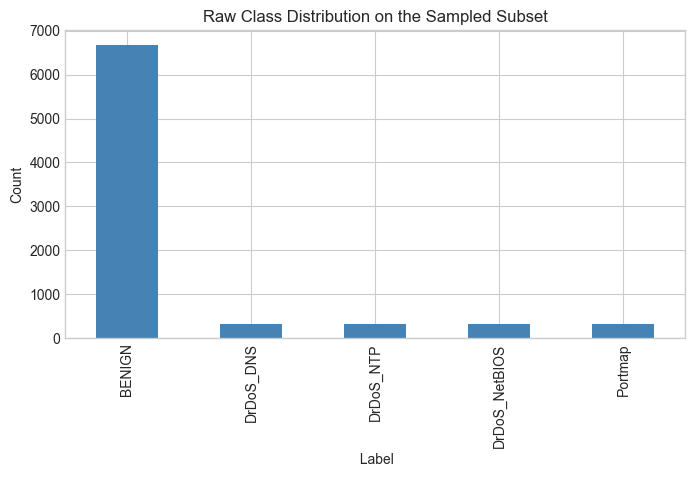

In [7]:
target_col_raw = raw_summary['target_column']
src_col_raw = [c for c in raw_df.columns if c.strip().lower() == 'source ip'][0]

schema_df = pd.DataFrame({
    'column': raw_df.columns,
    'dtype': raw_df.dtypes.astype(str).values,
    'missing': raw_df.isna().sum().values,
})

display(schema_df.head(20))
print('Duplicate rows in raw subset:', int(raw_df.duplicated().sum()))
print('Duplicate columns by content signature:', find_duplicate_columns(raw_df))
print('Raw source_ip availability:', raw_df[src_col_raw].notna().mean())

plt.figure(figsize=(8, 4))
raw_df[target_col_raw].astype(str).str.strip().value_counts().plot(kind='bar', color='steelblue')
plt.title('Raw Class Distribution on the Sampled Subset')
plt.ylabel('Count')
plt.show()

## Nettoyage et prétraitement avec contrôle du risque de fuite

Le nettoyage suit les mêmes principes de base que le pipeline principal du projet :
- standardiser les noms de colonnes
- convertir les champs de type objet à caractère numérique, comme `simillarhttp`
- supprimer les doublons et les colonnes dégénérées
- conserver `source_ip` et `timestamp` uniquement comme métadonnées
- exclure des entrées du modèle les identifiants et les colonnes à risque direct de fuite

In [8]:
clean_df, cleaning_summary = preprocess_dataframe(raw_df)
target_column = cleaning_summary['target_column']
feature_columns = select_feature_columns(clean_df, target_column)

print('Cleaned shape:', cleaning_summary['final_shape'])
print('Target column:', target_column)
print('Number of numeric modeling features:', len(feature_columns))
print('Converted columns:', cleaning_summary['converted_numeric_columns'])
print('Duplicate columns removed:', cleaning_summary['duplicate_columns_removed'])
print('Constant columns removed:', cleaning_summary['constant_columns_removed'])
print('Near-constant columns removed:', cleaning_summary['near_constant_columns_removed'])
print('Leakage-prone columns retained only as metadata if present:', cleaning_summary['candidate_leakage_columns'])

display(pd.DataFrame({'count': pd.Series(cleaning_summary['label_distribution_after_cleaning'])}))
display(pd.DataFrame({'missing_count': pd.Series(cleaning_summary['missing_values_top10'])}))

Cleaned shape: (8000, 72)
Target column: label
Number of numeric modeling features: 62
Converted columns: []
Duplicate columns removed: ['fwd_urg_flags', 'bwd_urg_flags', 'fin_flag_count', 'rst_flag_count', 'psh_flag_count', 'ece_flag_count', 'fwd_header_length_1', 'fwd_avg_bytes_bulk', 'fwd_avg_packets_bulk', 'fwd_avg_bulk_rate', 'bwd_avg_bytes_bulk', 'bwd_avg_packets_bulk', 'bwd_avg_bulk_rate', 'subflow_fwd_packets', 'subflow_bwd_packets']
Constant columns removed: ['bwd_psh_flags']
Near-constant columns removed: ['syn_flag_count']
Leakage-prone columns retained only as metadata if present: ['unnamed_0', 'flow_id', 'source_ip', 'destination_ip', 'source_port', 'destination_port', 'timestamp', 'simillarhttp']


,count
BENIGN,6672
DrDoS_DNS,332
DrDoS_NTP,332
DrDoS_NetBIOS,332
Portmap,332


,missing_count
simillarhttp,235
flow_bytes_s,127
flow_packets_s,127
unnamed_0,0
destination_ip,0
flow_id,0
source_ip,0
source_port,0
timestamp,0
protocol,0


## Diagnostics de structure de groupes avant modélisation

Cette section est placée volontairement **avant tout split train/test**. Son but est de vérifier si `source_ip` est suffisamment diversifié pour permettre une évaluation group-aware pertinente.

Nous examinons :
- le nombre de `source_ip` uniques par classe
- la distribution du nombre de lignes par groupe
- les plus grands groupes par classe
- des avertissements de concentration lorsqu’une classe est dominée par très peu de groupes

Group size mean: 25.24
Group size median: 2.0
Group size max: 2121
Classes with low source_ip diversity warning (< 3 groups): ['DrDoS_DNS', 'DrDoS_NTP', 'DrDoS_NetBIOS', 'Portmap']


,unique_source_ip
DrDoS_DNS,2
DrDoS_NTP,2
DrDoS_NetBIOS,2
Portmap,2
BENIGN,316


,largest_group_share
DrDoS_DNS,0.500000
DrDoS_NetBIOS,0.500000
DrDoS_NTP,0.500000
Portmap,0.500000
BENIGN,0.317896


,label,source_ip,rows,class_total_rows
138,BENIGN,192.168.50.6,2121,5352
140,BENIGN,192.168.50.8,1907,5352
139,BENIGN,192.168.50.7,1062,5352
141,BENIGN,192.168.50.9,135,5352
301,BENIGN,74.208.236.171,127,5352
316,DrDoS_DNS,172.16.0.5,166,332
317,DrDoS_DNS,192.168.50.1,166,332
318,DrDoS_NTP,172.16.0.5,166,332
319,DrDoS_NTP,192.168.50.1,166,332
320,DrDoS_NetBIOS,172.16.0.5,166,332


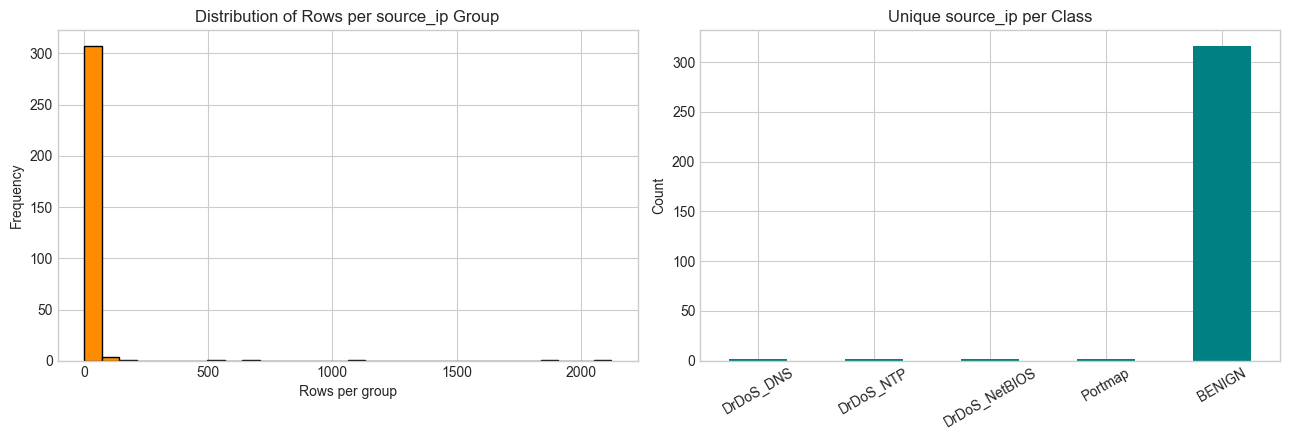

In [9]:
group_summary_raw, group_size_series, top_groups_df = summarize_group_structure(clean_df, target_column, group_column='source_ip')

unique_group_df = pd.DataFrame({'unique_source_ip': pd.Series(group_summary_raw['unique_groups_per_class'])}).sort_values('unique_source_ip')
concentration_df = pd.DataFrame({'largest_group_share': pd.Series(group_summary_raw['largest_group_share_by_class'])}).sort_values('largest_group_share', ascending=False)

print('Group size mean:', round(group_summary_raw['group_size_mean'], 2))
print('Group size median:', round(group_summary_raw['group_size_median'], 2))
print('Group size max:', group_summary_raw['group_size_max'])
print('Classes with low source_ip diversity warning (< 3 groups):', group_summary_raw['warning_classes'])

display(unique_group_df)
display(concentration_df)
display(top_groups_df.head(15))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(group_size_series.values, bins=30, color='darkorange', edgecolor='black')
axes[0].set_title('Distribution of Rows per source_ip Group')
axes[0].set_xlabel('Rows per group')
axes[0].set_ylabel('Frequency')

unique_group_df['unique_source_ip'].plot(kind='bar', ax=axes[1], color='teal')
axes[1].set_title('Unique source_ip per Class')
axes[1].set_ylabel('Count')
axes[1].tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

### Interprétation des diagnostics

Si une classe ne possède qu’un ou deux groupes `source_ip`, alors une évaluation strictement group-aware devient structurellement difficile. Cela **ne signifie pas** que la logique de split est incorrecte. Cela signifie que la portion du dataset elle-même offre une faible diversité de sources pour cette classe.

C’est précisément pour cette raison que les diagnostics de groupes doivent être vérifiés **avant** la modélisation, et non découverts seulement après l’effondrement des performances.

## Expérience A - Benchmark row-wise

Ce benchmark utilise un split stratifié row-wise classique. Il est utile pour valider le pipeline de bout en bout, mais il reste optimiste car le même `source_ip` peut apparaître à la fois dans train et dans test.

Row-wise train shape: (6400, 72)
Row-wise test shape: (1600, 72)
source_ip overlap across row-wise train/test: 100


,train,test
label,,
BENIGN,5337,1335
DrDoS_DNS,266,66
DrDoS_NTP,266,66
DrDoS_NetBIOS,265,67
Portmap,266,66


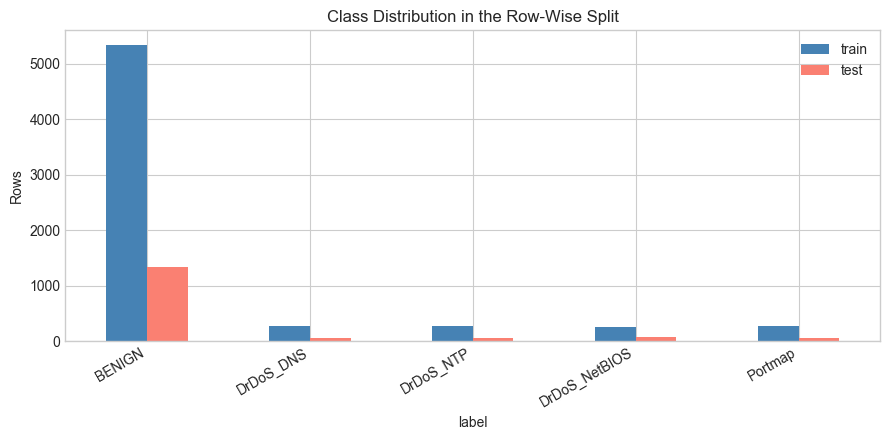

In [10]:
row_train_df, row_test_df = stratified_rowwise_split(clean_df, target_column, test_size=0.2)
row_class_split_df = pd.DataFrame({'train': row_train_df[target_column].value_counts(), 'test': row_test_df[target_column].value_counts()}).fillna(0).astype(int)
row_overlap = len(set(row_train_df['source_ip'].dropna()) & set(row_test_df['source_ip'].dropna()))

print('Row-wise train shape:', row_train_df.shape)
print('Row-wise test shape:', row_test_df.shape)
print('source_ip overlap across row-wise train/test:', row_overlap)
display(row_class_split_df)

row_class_split_df.plot(kind='bar', figsize=(9, 4.5), color=['steelblue', 'salmon'])
plt.title('Class Distribution in the Row-Wise Split')
plt.ylabel('Rows')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

### Modèles row-wise : Logistic Regression, Random Forest et LSTM

L’ajout de Random Forest permet de vérifier si une baseline tabulaire forte peut surpasser à la fois un modèle linéaire et le LSTM sur le même split.

Row-wise LSTM validation strategy: group_aware


,model,accuracy,weighted_f1,macro_f1
1,Random Forest,0.9712,0.9707,0.8701
2,LSTM,0.9038,0.8901,0.4969
0,Logistic Regression,0.8775,0.8884,0.5830


,feature,importance
45,avg_fwd_segment_size,0.072793
35,min_packet_length,0.067879
37,packet_length_mean,0.063238
8,fwd_packet_length_mean,0.061376
7,fwd_packet_length_min,0.059118
6,fwd_packet_length_max,0.054928
44,average_packet_size,0.052508
52,min_seg_size_forward,0.048613
31,fwd_header_length,0.044582
36,max_packet_length,0.037597


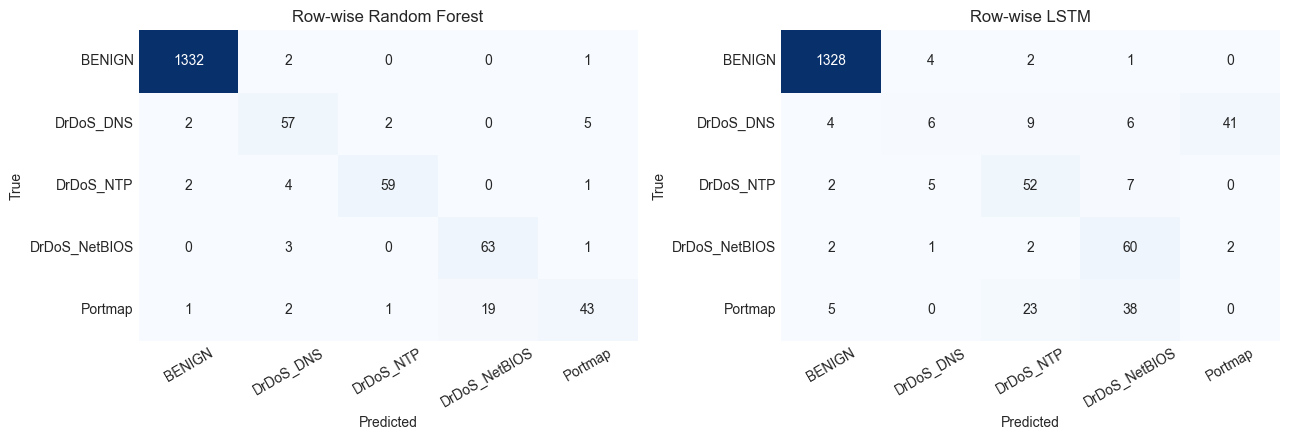

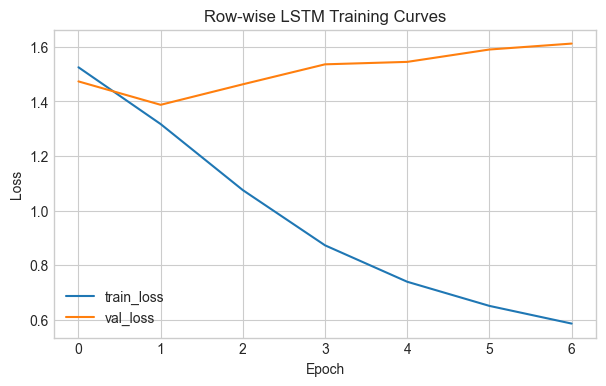

In [11]:
row_log_model, row_log_metrics, row_prepared = train_logistic(row_train_df, row_test_df, target_column, feature_columns)
row_rf_model, row_rf_metrics, row_rf_prepared, row_rf_importance = train_random_forest(row_train_df, row_test_df, target_column, feature_columns)
row_lstm_model, row_lstm_metrics, row_lstm_histories, row_lstm_prepared, row_validation_diag = train_lstm(row_train_df, row_test_df, target_column, feature_columns, sequence_lengths=[ROWWISE_SEQUENCE_LENGTH])

row_results_df = pd.DataFrame([
    {'model': 'Logistic Regression', 'accuracy': row_log_metrics['accuracy'], 'weighted_f1': row_log_metrics['f1_weighted'], 'macro_f1': row_log_metrics['f1_macro']},
    {'model': 'Random Forest', 'accuracy': row_rf_metrics['accuracy'], 'weighted_f1': row_rf_metrics['f1_weighted'], 'macro_f1': row_rf_metrics['f1_macro']},
    {'model': 'LSTM', 'accuracy': row_lstm_metrics['accuracy'], 'weighted_f1': row_lstm_metrics['f1_weighted'], 'macro_f1': row_lstm_metrics['f1_macro']},
]).sort_values('weighted_f1', ascending=False).round(4)

print('Row-wise LSTM validation strategy:', row_lstm_metrics['validation_strategy'])
display(row_results_df)
display(row_rf_importance.head(10))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
plot_confusion(axes[0], np.array(row_rf_metrics['confusion_matrix']), row_rf_prepared['label_encoder'].classes_, 'Row-wise Random Forest')
plot_confusion(axes[1], np.array(row_lstm_metrics['confusion_matrix']), row_lstm_prepared['label_encoder'].classes_, 'Row-wise LSTM')
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
row_history_key = (row_lstm_metrics['best_sequence_length'], row_lstm_metrics['best_hidden_size'], row_lstm_metrics['best_dropout'])
row_history = row_lstm_histories[row_history_key]
plt.plot(row_history['train_loss'], label='train_loss')
plt.plot(row_history['val_loss'], label='val_loss')
plt.title('Row-wise LSTM Training Curves')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

## Expérience B - Évaluation de robustesse group-aware

Cette expérience utilise `source_ip` comme clé de regroupement et valide explicitement la qualité du split avant l’entraînement.

### Méthode utilisée et justification
L’idée est de ne pas accepter automatiquement le premier split group-aware obtenu. À la place, le notebook :
- teste plusieurs graines aléatoires avec `GroupShuffleSplit`
- rejette les splits avec overlap de groupes ou classes absentes
- évalue les candidats faisables selon leur proximité avec la taille de test demandée
- signale lorsque le meilleur split reste structurellement limité par le dataset

Cette démarche permet de mieux contrôler la qualité du protocole d’évaluation et de rendre l’interprétation des résultats plus fiable.

Group-aware split status: valid
Exact source_ip overlap: 0
Class presence in both splits: True
Observed test ratio: 0.2028
Train unique groups: 12
Test unique groups: 305


,train,test
label,,
BENIGN,5714,958
DrDoS_DNS,166,166
DrDoS_NTP,166,166
DrDoS_NetBIOS,166,166
Portmap,166,166


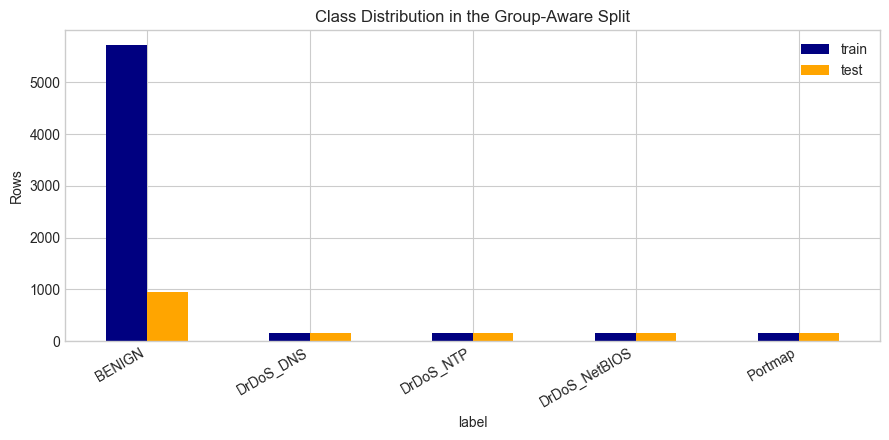

Split construction: class_covering_seeded
Minimum test support across present classes: 166


In [12]:
group_train_df, group_test_df, group_split_diag = robust_group_split(clean_df, target_column, group_column='source_ip', test_size=GROUP_TEST_SIZE, n_trials=150)
group_class_split_df = pd.DataFrame({'train': group_train_df[target_column].value_counts(), 'test': group_test_df[target_column].value_counts()}).fillna(0).astype(int)

print('Group-aware split status:', group_split_diag['status'])
print('Exact source_ip overlap:', group_split_diag['overlap'])
print('Class presence in both splits:', group_split_diag['class_presence_ok'])
print('Observed test ratio:', round(group_split_diag['test_ratio'], 4))
print('Train unique groups:', group_split_diag['train_groups'])
print('Test unique groups:', group_split_diag['test_groups'])
display(group_class_split_df)

group_class_split_df.plot(kind='bar', figsize=(9, 4.5), color=['navy', 'orange'])
plt.title('Class Distribution in the Group-Aware Split')
plt.ylabel('Rows')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()
print('Split construction:', group_split_diag.get('construction'))
print('Minimum test support across present classes:', group_split_diag.get('min_test_class_support'))

### Modèles group-aware : Logistic Regression, Random Forest et LSTM

L’évaluation group-aware est le protocole le plus réaliste pour cette portion du dataset, car elle empêche le même `source_ip` d’apparaître dans train et dans test.

Le notebook essaie également de rendre la **validation du LSTM group-aware**. Si cela devient impossible après le split externe, le notebook le signale explicitement et bascule sur une validation interne dans la partition d’entraînement au lieu de masquer le problème.

**Remarque :** si le statut du split est `fallback_best_feasible`, le notebook continue volontairement afin que la limitation structurelle soit documentée au lieu d’être cachée.

Internal validation strategy for the strict protocol: rowwise_fallback_due_to_group_infeasibility
Validation warning: Class-preserving group-aware validation was infeasible inside the training partition.
Best group-aware LSTM sequence length: 10


,model,accuracy,weighted_f1,macro_f1
1,Random Forest,0.8255,0.8005,0.6500
2,LSTM,0.6782,0.6257,0.3245
0,Logistic Regression,0.6702,0.5648,0.3076


,feature,importance
35,min_packet_length,0.070914
7,fwd_packet_length_min,0.058819
45,avg_fwd_segment_size,0.049873
49,init_win_bytes_forward,0.046951
44,average_packet_size,0.044907
52,min_seg_size_forward,0.044886
8,fwd_packet_length_mean,0.044315
37,packet_length_mean,0.043965
31,fwd_header_length,0.037897
4,total_length_of_fwd_packets,0.036875


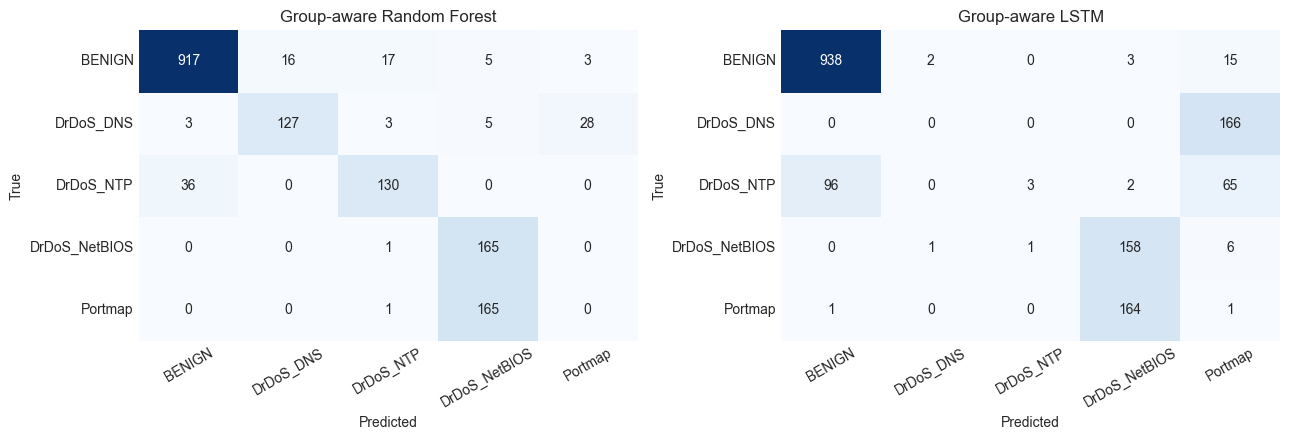

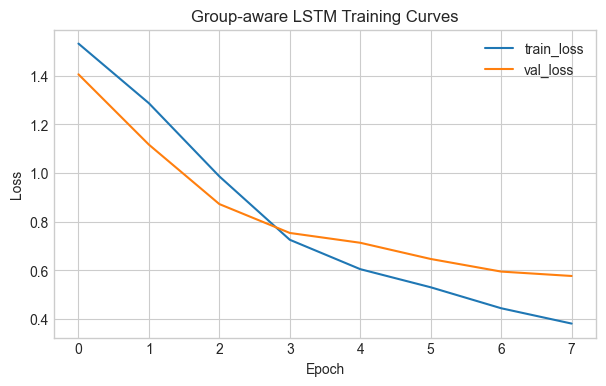

In [13]:
group_log_model, group_log_metrics, group_log_prepared = train_logistic(group_train_df, group_test_df, target_column, feature_columns)
group_rf_model, group_rf_metrics, group_rf_prepared, group_rf_importance = train_random_forest(group_train_df, group_test_df, target_column, feature_columns)
group_lstm_model, group_lstm_metrics, group_lstm_histories, group_lstm_prepared, group_validation_diag = train_lstm(group_train_df, group_test_df, target_column, feature_columns, sequence_lengths=GROUP_SEQUENCE_LENGTHS)

group_results_df = pd.DataFrame([
    {'model': 'Logistic Regression', 'accuracy': group_log_metrics['accuracy'], 'weighted_f1': group_log_metrics['f1_weighted'], 'macro_f1': group_log_metrics['f1_macro']},
    {'model': 'Random Forest', 'accuracy': group_rf_metrics['accuracy'], 'weighted_f1': group_rf_metrics['f1_weighted'], 'macro_f1': group_rf_metrics['f1_macro']},
    {'model': 'LSTM', 'accuracy': group_lstm_metrics['accuracy'], 'weighted_f1': group_lstm_metrics['f1_weighted'], 'macro_f1': group_lstm_metrics['f1_macro']},
]).sort_values('weighted_f1', ascending=False).round(4)

print('Internal validation strategy for the strict protocol:', group_lstm_metrics['validation_strategy'])
if 'validation_warning' in group_lstm_metrics:
    print('Validation warning:', group_lstm_metrics['validation_warning'])
print('Best group-aware LSTM sequence length:', group_lstm_metrics['best_sequence_length'])
display(group_results_df)
display(group_rf_importance.head(10))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
plot_confusion(axes[0], np.array(group_rf_metrics['confusion_matrix']), group_rf_prepared['label_encoder'].classes_, 'Group-aware Random Forest')
plot_confusion(axes[1], np.array(group_lstm_metrics['confusion_matrix']), group_lstm_prepared['label_encoder'].classes_, 'Group-aware LSTM')
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
group_history_key = (group_lstm_metrics['best_sequence_length'], group_lstm_metrics['best_hidden_size'], group_lstm_metrics['best_dropout'])
best_history = group_lstm_histories[group_history_key]
plt.plot(best_history['train_loss'], label='train_loss')
plt.plot(best_history['val_loss'], label='val_loss')
plt.title('Group-aware LSTM Training Curves')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

## Robustesse des features et ablation des raccourcis

Cette section étend l’étude d’ablation autour de la feature `inbound` en utilisant le classement d’importance du Random Forest group-aware pour identifier une autre feature potentiellement dominante, puis en réalisant une ablation sur ces deux configurations.

L’objectif est de vérifier si le modèle exploite des raccourcis liés au dataset ou s’il apprend réellement un comportement d’attaque plus stable. Cette approche reste légère en calcul tout en apportant une information méthodologique importante.

,experiment,dropped_features,accuracy,weighted_f1,macro_f1
0,full_features,(none),0.6702,0.5648,0.3076
1,without_inbound,inbound,0.3588,0.3908,0.3308
2,without_top_non_inbound,min_packet_length,0.6702,0.5648,0.3073


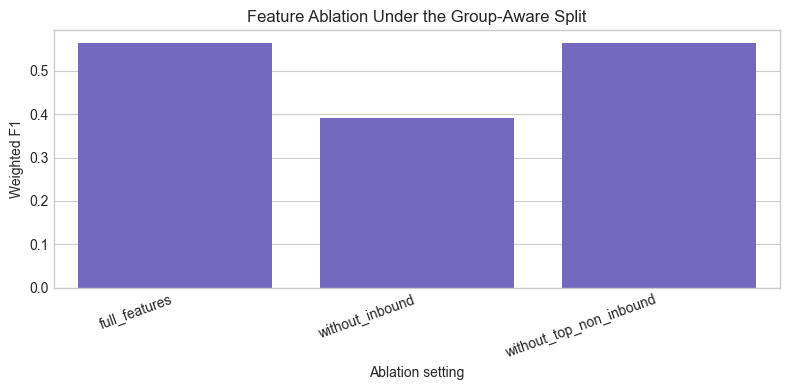

In [14]:
top_shortcut_candidates = group_rf_importance['feature'].head(6).tolist()
secondary_candidate = next((feature for feature in top_shortcut_candidates if feature != 'inbound'), None)

ablation_specs = [
    ('full_features', []),
    ('without_inbound', ['inbound'] if 'inbound' in feature_columns else []),
]
if secondary_candidate is not None:
    ablation_specs.append(('without_top_non_inbound', [secondary_candidate]))

ablation_rows = []
for name, dropped in ablation_specs:
    subset_features = [f for f in feature_columns if f not in dropped]
    _, ab_metrics, _ = train_logistic(group_train_df, group_test_df, target_column, subset_features)
    ablation_rows.append({
        'experiment': name,
        'dropped_features': ', '.join(dropped) if dropped else '(none)',
        'accuracy': ab_metrics['accuracy'],
        'weighted_f1': ab_metrics['f1_weighted'],
        'macro_f1': ab_metrics['f1_macro'],
    })

ablation_df = pd.DataFrame(ablation_rows).round(4)
display(ablation_df)

plt.figure(figsize=(8, 4))
sns.barplot(data=ablation_df, x='experiment', y='weighted_f1', color='slateblue')
plt.title('Feature Ablation Under the Group-Aware Split')
plt.ylabel('Weighted F1')
plt.xlabel('Ablation setting')
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.show()

## Tuning et optimisation des hyperparamètres

Cette section complète le notebook en ajoutant une phase de **tuning réelle mais légère**.

### Pourquoi Random Forest est la cible principale du tuning
Random Forest est la baseline tabulaire la plus forte de cette étude, et CIC-DDoS2019 reste fondamentalement un dataset tabulaire de flux. Pour cette raison, Random Forest constitue la cible principale du tuning.

### Pourquoi le tuning du LSTM reste léger
Le tuning du LSTM est inclus comme expérience secondaire. L’objectif n’est pas de lancer une recherche massive et coûteuse, mais de vérifier de manière contrôlée si des ajustements modérés améliorent réellement le modèle.

### Tuning de Random Forest

La recherche sur Random Forest est effectuée sur le **split d’entraînement row-wise** avec `RandomizedSearchCV`, une validation croisée stratifiée à 3 folds, et le **weighted F1** comme critère d’optimisation. La meilleure configuration est ensuite réévaluée sous le protocole group-aware comme test de robustesse.

Best Random Forest parameters: {'n_estimators': 150, 'min_samples_split': 4, 'min_samples_leaf': 1, 'max_features': 0.5, 'max_depth': 24}
Best cross-validation weighted F1: nan


,setting,accuracy,weighted_f1,macro_f1
0,Random Forest default (row-wise),0.9712,0.9707,0.8701
1,Random Forest tuned (row-wise),0.9712,0.9708,0.8660
2,Random Forest default (group-aware),0.8255,0.8005,0.6500
3,Random Forest tuned (group-aware),0.8268,0.8014,0.6668


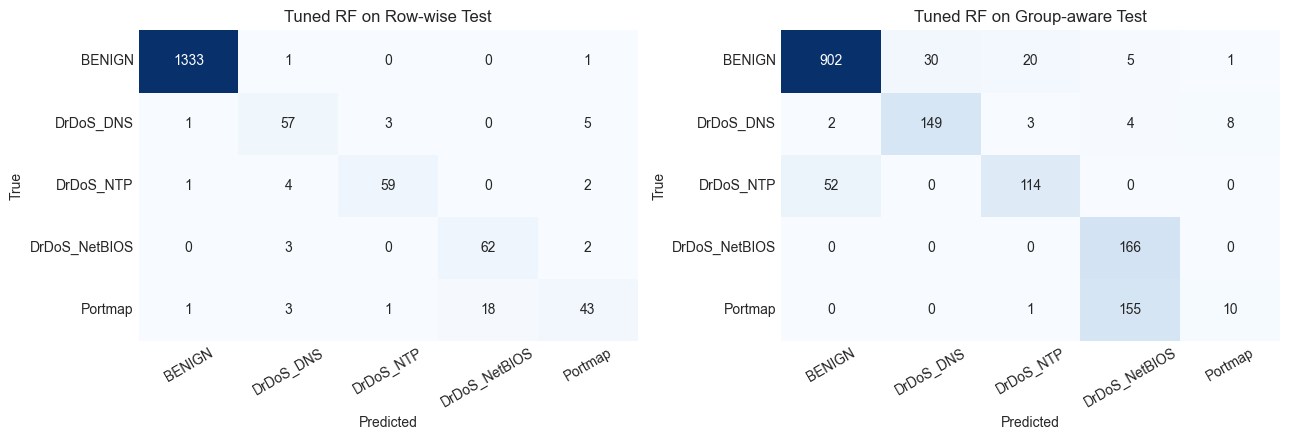

In [15]:
row_rf_tuned_model, row_rf_tuned_metrics, row_rf_search = tune_random_forest_rowwise(row_train_df, row_test_df, target_column, feature_columns, n_iter=10)
_, group_rf_tuned_metrics, _, group_rf_tuned_importance = train_random_forest(group_train_df, group_test_df, target_column, feature_columns, rf_params=row_rf_tuned_metrics['best_params'])

rf_tuning_summary_df = pd.DataFrame([
    {'setting': 'Random Forest default (row-wise)', 'accuracy': row_rf_metrics['accuracy'], 'weighted_f1': row_rf_metrics['f1_weighted'], 'macro_f1': row_rf_metrics['f1_macro']},
    {'setting': 'Random Forest tuned (row-wise)', 'accuracy': row_rf_tuned_metrics['accuracy'], 'weighted_f1': row_rf_tuned_metrics['f1_weighted'], 'macro_f1': row_rf_tuned_metrics['f1_macro']},
    {'setting': 'Random Forest default (group-aware)', 'accuracy': group_rf_metrics['accuracy'], 'weighted_f1': group_rf_metrics['f1_weighted'], 'macro_f1': group_rf_metrics['f1_macro']},
    {'setting': 'Random Forest tuned (group-aware)', 'accuracy': group_rf_tuned_metrics['accuracy'], 'weighted_f1': group_rf_tuned_metrics['f1_weighted'], 'macro_f1': group_rf_tuned_metrics['f1_macro']},
]).round(4)

print('Best Random Forest parameters:', row_rf_tuned_metrics['best_params'])
print('Best cross-validation weighted F1:', round(row_rf_tuned_metrics['best_cv_weighted_f1'], 4))
display(rf_tuning_summary_df)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
plot_confusion(axes[0], np.array(row_rf_tuned_metrics['confusion_matrix']), row_rf_prepared['label_encoder'].classes_, 'Tuned RF on Row-wise Test')
plot_confusion(axes[1], np.array(group_rf_tuned_metrics['confusion_matrix']), group_rf_prepared['label_encoder'].classes_, 'Tuned RF on Group-aware Test')
plt.tight_layout()
plt.show()

### Tuning léger du LSTM

Le tuning du LSTM reste volontairement petit et contrôlé :
- longueur de séquence : `5`, `10`, `15`
- taille cachée : `32`, `64`
- dropout : `0.2`, `0.3`

Cela suffit pour tester si un tuning modéré aide réellement, tout en gardant un temps d’exécution raisonnable pour un environnement notebook.

Best row-wise LSTM config: {'sequence_length': 15, 'hidden_size': 64, 'dropout': 0.2, 'validation_weighted_f1': 0.7622}
Best group-aware LSTM config: {'sequence_length': 10, 'hidden_size': 32, 'dropout': 0.2, 'validation_weighted_f1': 0.9709}


,setting,accuracy,weighted_f1,macro_f1
0,LSTM default (row-wise),0.9038,0.8901,0.4969
1,LSTM tuned (row-wise),0.8750,0.8642,0.3689
2,LSTM default (group-aware),0.6782,0.6257,0.3245
3,LSTM tuned (group-aware),0.6899,0.6352,0.3525


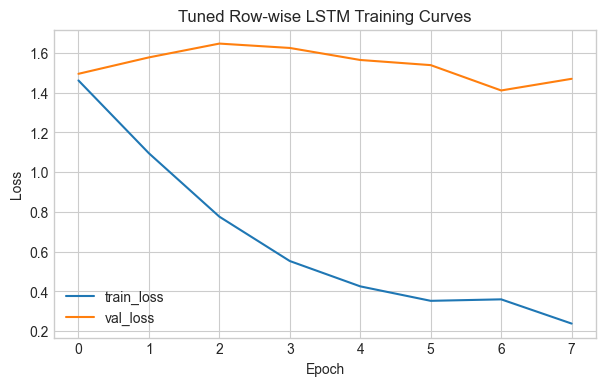

In [16]:
row_lstm_tuned_model, row_lstm_tuned_metrics, row_lstm_tuned_histories, row_lstm_tuned_prepared, row_lstm_tuned_val_diag = train_lstm(
    row_train_df,
    row_test_df,
    target_column,
    feature_columns,
    sequence_lengths=[5, 10, 15],
    hidden_sizes=[32, 64],
    dropouts=[0.2, 0.3],
)

group_lstm_tuned_model, group_lstm_tuned_metrics, group_lstm_tuned_histories, group_lstm_tuned_prepared, group_lstm_tuned_val_diag = train_lstm(
    group_train_df,
    group_test_df,
    target_column,
    feature_columns,
    sequence_lengths=[5, 10, 15],
    hidden_sizes=[32, 64],
    dropouts=[0.2, 0.3],
)

lstm_tuning_summary_df = pd.DataFrame([
    {'setting': 'LSTM default (row-wise)', 'accuracy': row_lstm_metrics['accuracy'], 'weighted_f1': row_lstm_metrics['f1_weighted'], 'macro_f1': row_lstm_metrics['f1_macro']},
    {'setting': 'LSTM tuned (row-wise)', 'accuracy': row_lstm_tuned_metrics['accuracy'], 'weighted_f1': row_lstm_tuned_metrics['f1_weighted'], 'macro_f1': row_lstm_tuned_metrics['f1_macro']},
    {'setting': 'LSTM default (group-aware)', 'accuracy': group_lstm_metrics['accuracy'], 'weighted_f1': group_lstm_metrics['f1_weighted'], 'macro_f1': group_lstm_metrics['f1_macro']},
    {'setting': 'LSTM tuned (group-aware)', 'accuracy': group_lstm_tuned_metrics['accuracy'], 'weighted_f1': group_lstm_tuned_metrics['f1_weighted'], 'macro_f1': group_lstm_tuned_metrics['f1_macro']},
]).round(4)

print('Best row-wise LSTM config:', {
    'sequence_length': row_lstm_tuned_metrics['best_sequence_length'],
    'hidden_size': row_lstm_tuned_metrics['best_hidden_size'],
    'dropout': row_lstm_tuned_metrics['best_dropout'],
    'validation_weighted_f1': round(row_lstm_tuned_metrics['best_validation_weighted_f1'], 4),
})
print('Best group-aware LSTM config:', {
    'sequence_length': group_lstm_tuned_metrics['best_sequence_length'],
    'hidden_size': group_lstm_tuned_metrics['best_hidden_size'],
    'dropout': group_lstm_tuned_metrics['best_dropout'],
    'validation_weighted_f1': round(group_lstm_tuned_metrics['best_validation_weighted_f1'], 4),
})
display(lstm_tuning_summary_df)

best_row_config = (row_lstm_tuned_metrics['best_sequence_length'], row_lstm_tuned_metrics['best_hidden_size'], row_lstm_tuned_metrics['best_dropout'])
plt.figure(figsize=(7, 4))
plt.plot(row_lstm_tuned_histories[best_row_config]['train_loss'], label='train_loss')
plt.plot(row_lstm_tuned_histories[best_row_config]['val_loss'], label='val_loss')
plt.title('Tuned Row-wise LSTM Training Curves')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

## Comparaison des performances entre modèles et protocoles

Cette section met les deux protocoles d’évaluation côte à côte. La question centrale n’est pas de savoir quel modèle obtient le plus grand score dans le benchmark facile, mais quelles conclusions restent crédibles lorsque les chemins de fuite potentiels sont réduits.

,protocol,model,accuracy,weighted_f1,macro_f1
0,Row-wise benchmark,Logistic Regression,0.8775,0.8884,0.5830
1,Row-wise benchmark,Random Forest default,0.9712,0.9707,0.8701
2,Row-wise benchmark,Random Forest tuned,0.9712,0.9708,0.8660
3,Row-wise benchmark,LSTM default,0.9038,0.8901,0.4969
4,Row-wise benchmark,LSTM tuned,0.8750,0.8642,0.3689
5,Group-aware robustness,Logistic Regression,0.6702,0.5648,0.3076
6,Group-aware robustness,Random Forest default,0.8255,0.8005,0.6500
7,Group-aware robustness,Random Forest tuned,0.8268,0.8014,0.6668
8,Group-aware robustness,LSTM default,0.6782,0.6257,0.3245
9,Group-aware robustness,LSTM tuned,0.6899,0.6352,0.3525


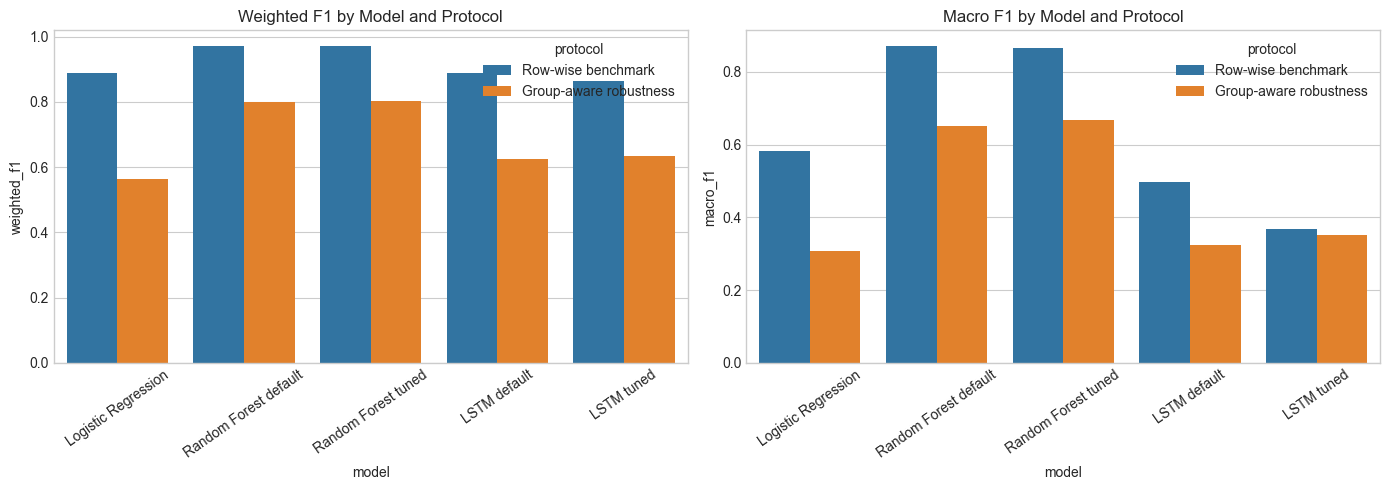

In [17]:
comparison_df = pd.DataFrame([
    {'protocol': 'Row-wise benchmark', 'model': 'Logistic Regression', 'accuracy': row_log_metrics['accuracy'], 'weighted_f1': row_log_metrics['f1_weighted'], 'macro_f1': row_log_metrics['f1_macro']},
    {'protocol': 'Row-wise benchmark', 'model': 'Random Forest default', 'accuracy': row_rf_metrics['accuracy'], 'weighted_f1': row_rf_metrics['f1_weighted'], 'macro_f1': row_rf_metrics['f1_macro']},
    {'protocol': 'Row-wise benchmark', 'model': 'Random Forest tuned', 'accuracy': row_rf_tuned_metrics['accuracy'], 'weighted_f1': row_rf_tuned_metrics['f1_weighted'], 'macro_f1': row_rf_tuned_metrics['f1_macro']},
    {'protocol': 'Row-wise benchmark', 'model': 'LSTM default', 'accuracy': row_lstm_metrics['accuracy'], 'weighted_f1': row_lstm_metrics['f1_weighted'], 'macro_f1': row_lstm_metrics['f1_macro']},
    {'protocol': 'Row-wise benchmark', 'model': 'LSTM tuned', 'accuracy': row_lstm_tuned_metrics['accuracy'], 'weighted_f1': row_lstm_tuned_metrics['f1_weighted'], 'macro_f1': row_lstm_tuned_metrics['f1_macro']},
    {'protocol': 'Group-aware robustness', 'model': 'Logistic Regression', 'accuracy': group_log_metrics['accuracy'], 'weighted_f1': group_log_metrics['f1_weighted'], 'macro_f1': group_log_metrics['f1_macro']},
    {'protocol': 'Group-aware robustness', 'model': 'Random Forest default', 'accuracy': group_rf_metrics['accuracy'], 'weighted_f1': group_rf_metrics['f1_weighted'], 'macro_f1': group_rf_metrics['f1_macro']},
    {'protocol': 'Group-aware robustness', 'model': 'Random Forest tuned', 'accuracy': group_rf_tuned_metrics['accuracy'], 'weighted_f1': group_rf_tuned_metrics['f1_weighted'], 'macro_f1': group_rf_tuned_metrics['f1_macro']},
    {'protocol': 'Group-aware robustness', 'model': 'LSTM default', 'accuracy': group_lstm_metrics['accuracy'], 'weighted_f1': group_lstm_metrics['f1_weighted'], 'macro_f1': group_lstm_metrics['f1_macro']},
    {'protocol': 'Group-aware robustness', 'model': 'LSTM tuned', 'accuracy': group_lstm_tuned_metrics['accuracy'], 'weighted_f1': group_lstm_tuned_metrics['f1_weighted'], 'macro_f1': group_lstm_tuned_metrics['f1_macro']},
]).round(4)

display(comparison_df)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=comparison_df, x='model', y='weighted_f1', hue='protocol', ax=axes[0])
axes[0].set_title('Weighted F1 by Model and Protocol')
axes[0].tick_params(axis='x', rotation=35)

sns.barplot(data=comparison_df, x='model', y='macro_f1', hue='protocol', ax=axes[1])
axes[1].set_title('Macro F1 by Model and Protocol')
axes[1].tick_params(axis='x', rotation=35)
plt.tight_layout()
plt.show()

## Interprétation académique

### Pourquoi l’évaluation row-wise est optimiste
Le split row-wise permet à des flux très proches provenant du même `source_ip` d’apparaître dans train et dans test. Cela rend le problème plus facile que dans des conditions réelles, surtout lorsque le dataset contient des sources d’attaque répétées ou très concentrées.

### Pourquoi l’évaluation group-aware est plus réaliste
Un split fondé sur `source_ip` supprime ce raccourci et teste si le modèle généralise vers des groupes jamais vus. Si la performance s’effondre, cela ne signifie pas automatiquement que le modèle est inutile. Cela signifie que le benchmark précédent ne mesurait pas le même type de généralisation.

### Interprétation du tuning
Les résultats du tuning doivent être lus à deux niveaux :
- les **gains de tuning row-wise** montrent si la famille de modèles possédait encore une marge sous le protocole de benchmark le plus facile
- les **résultats tuned en group-aware** montrent si ces gains survivent à un test de robustesse plus réaliste

Si Random Forest ajusté reste le meilleur modèle après tuning, cela renforce la conclusion que ce dataset se comporte principalement comme un problème de classification tabulaire. Si les gains du LSTM tuned sont faibles ou instables, cela soutient une interprétation prudente de l’usage du LSTM sur CIC-DDoS2019.

### Pourquoi la performance peut encore s’effondrer après tuning
De meilleurs hyperparamètres ne suppriment pas les limites du dataset. Si les classes d’attaque elles-mêmes sont liées à très peu de groupes sources, alors l’évaluation strictement group-aware restera difficile même après un tuning correct. Dans ce cas, la bonne conclusion n’est pas de masquer l’effondrement, mais de le rapporter honnêtement comme une limite structurelle des données.

## Conclusion finale

Ce notebook fournit maintenant un workflow expérimental plus complet couvrant l’ensemble des attentes du projet.

### Ce qui est couvert
- prétraitement et nettoyage avec contrôle du risque de fuite
- entraînement des modèles
- test des modèles
- évaluation des modèles
- tuning et optimisation

### Ce qui a été amélioré
- L’échantillonnage couvre une portion plus large de chaque fichier tout en restant pratique.
- La structure par groupes est diagnostiquée avant la modélisation.
- Le split group-aware est validé au lieu d’être accepté aveuglément.
- Random Forest a été ajouté comme baseline tabulaire plus forte.
- Le tuning des hyperparamètres a été ajouté sous une forme légère mais réelle, avec Random Forest comme cible principale et LSTM comme modèle secondaire ajusté.
- L’ablation de features a été étendue au-delà d’une seule hypothèse de raccourci.
- Les visualisations comparent maintenant plus clairement les protocoles, la structure des groupes, l’équilibre des classes, les modèles par défaut et les modèles tuned.

